# Emotion recognition with MobileNetV3 — partial fine-tuning


## 1. Environment


In [ ]:
import csv, hashlib, json, os, platform, random, shutil, subprocess, sys, tarfile, time, zipfile
from collections import Counter, defaultdict
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.models import (MobileNet_V3_Large_Weights, MobileNet_V3_Small_Weights,
                                mobilenet_v3_large, mobilenet_v3_small)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Python:', platform.python_version(), '| torch:', torch.__version__,
      '| torchvision:', torchvision.__version__, '| OpenCV:', cv2.__version__, '| NumPy:', np.__version__)
print('CUDA:', torch.version.cuda, '| GPU:', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'none')
if DEVICE.type == 'cuda':
    print('GPU memory (GiB):', round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1))
print('Free disk (GiB):', round(shutil.disk_usage(Path.cwd()).free / 2**30, 1))

probe = mobilenet_v3_small(num_classes=6).to(DEVICE)
probe(torch.randn(2, 3, 224, 224, device=DEVICE)).sum().backward()
del probe
print('MobileNetV3 forward/backward check passed.')


Python: 3.13.16 | torch: 2.14.1+cu130 | torchvision: 0.29.1+cu130 | OpenCV: 4.14.0 | NumPy: 2.4.6
CUDA: 13.0 | GPU: Tesla T4
GPU memory (GiB): 14.6
Free disk (GiB): 112.4
MobileNetV3 forward/backward check passed.


## 2. Configuration and persistent storage


In [ ]:
try:
    from google.colab import drive, files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

RUN_MODE = 'train'
UNFREEZE_LAST_BLOCKS = 6
COMPARE_SMALL_MODELS = False
RUN_NAME = f'emotion_mobilenetv3_6class_partial_last{UNFREEZE_LAST_BLOCKS}'
if not COMPARE_SMALL_MODELS:
    RUN_NAME += '_ls005'
USE_DRIVE = True
FER2013_CSV = ''
USE_KAGGLE_API = False
ALLOW_PROTOCOL_B = True
PROTOCOL_B_DIR = ''
UPLOAD_DEMO = False
KAGGLE_COMPETITION = 'challenges-in-representation-learning-facial-expression-recognition-challenge'
PROTOCOL_B_DATASET = 'msambare/fer2013'

if IN_COLAB and USE_DRIVE:
    drive.mount('/content/drive')
    PERSIST = Path('/content/drive/MyDrive') / RUN_NAME
else:
    PERSIST = (Path('/content') if IN_COLAB else Path.cwd()) / RUN_NAME
ROOT = Path('/content/emotion') if IN_COLAB else Path.cwd() / 'emotion_work'
for path in (ROOT, PERSIST):
    path.mkdir(parents=True, exist_ok=True)

FER2013_CLASS_NAMES = ['angry', 'disgust', 'fear', 'happy', 'sad', 'surprise', 'neutral']
CLASS_NAMES = ['angry', 'fear', 'happy', 'sad', 'surprise', 'neutral']
SOURCE_TO_MODEL_ID = {i: CLASS_NAMES.index(name) for i, name in enumerate(FER2013_CLASS_NAMES) if name in CLASS_NAMES}
UI_LABELS = [name.capitalize() for name in CLASS_NAMES]
NUM_CLASSES = len(CLASS_NAMES)
SEED = 42
SOURCE_SIZE = 48
INPUT_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
BLANK_STD = 1.0
PROTOCOL_B_VAL_FRACTION = 0.10
BATCH = 64
WARMUP_EPOCHS = 3
FINETUNE_EPOCHS = 25
HEAD_LR, BACKBONE_LR, CLASSIFIER_LR = 1e-3, 1e-4, 3e-4
WEIGHT_DECAY = 1e-4
PLATEAU_PATIENCE, PLATEAU_FACTOR = 2, 0.5
EARLY_STOP_PATIENCE, MIN_DELTA = 6, 0.001
AUGMENT = dict(flip_p=0.5, max_rotation_deg=10, max_translate=0.05, brightness=0.15, contrast=0.15)
LARGE_MARGIN = 0.01
CPU_P95_BUDGET_MS = 50.0
TARGET_ACCEPTED_ACCURACY = 0.80
THRESHOLDS = [round(0.05 * i, 2) for i in range(20)]
MIN_CROP_SIDE = 16
SMOKE_TRAIN_PER_CLASS, SMOKE_VAL_PER_CLASS = 100, 25
EXPERIMENTS = {
    'E1': dict(arch='small', weighted=False),
    'E2': dict(arch='small', weighted=True),
    'E3': dict(arch='large', weighted=None),
}
assert RUN_MODE in {'smoke', 'train', 'evaluate'}
assert isinstance(UNFREEZE_LAST_BLOCKS, int) and UNFREEZE_LAST_BLOCKS > 0
assert len(set(CLASS_NAMES)) == NUM_CLASSES == 6

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
print('Mode:', RUN_MODE, '| Device:', DEVICE, '| Persistent outputs:', PERSIST)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Mode: train | Device: cuda | Persistent outputs: /content/drive/MyDrive/emotion_mobilenetv3_6class_partial_last6_ls005


## 3. Dataset acquisition


In [ ]:
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def is_archive(path):
    return path.is_file() and path.name.lower().endswith(('.zip', '.tar', '.tar.gz', '.tgz'))

def safe_extract(archive, destination):

    marker = destination / '.extraction_complete.json'
    digest = sha256_file(archive)
    if marker.exists() and json.loads(marker.read_text()) == {'sha256': digest}:
        return destination
    destination.mkdir(parents=True, exist_ok=True)
    base = destination.resolve()
    def inside(name):
        target = (destination / name).resolve()
        return target == base or base in target.parents
    if zipfile.is_zipfile(archive):
        with zipfile.ZipFile(archive) as z:
            assert all(inside(name) for name in z.namelist()), f'Unsafe path in {archive}'
            z.extractall(destination)
    else:
        with tarfile.open(archive) as t:
            members = t.getmembers()
            assert all(inside(m.name) and (m.isfile() or m.isdir()) for m in members), f'Unsafe member in {archive}'
            t.extractall(destination, members=members, **({'filter': 'data'} if hasattr(tarfile, 'data_filter') else {}))

    marker.write_text(json.dumps({'sha256': digest}))
    return destination

def locate_csv(path, depth=0):

    path = Path(path)
    if path.is_file() and path.suffix.lower() == '.csv':
        return path
    if is_archive(path) and depth < 3:
        path = safe_extract(path, ROOT / 'extracted' / path.name.split('.')[0])
    if path.is_dir():
        matches = sorted(path.rglob('fer2013.csv'))
        if matches:
            return matches[0]
        for inner in sorted(p for p in path.rglob('*') if is_archive(p)):
            found = locate_csv(inner, depth + 1) if depth < 3 else None
            if found:
                return found
    return None

def kaggle_competition_download():
    config = Path.home() / '.kaggle' / 'kaggle.json'
    if not config.exists():
        assert IN_COLAB, 'Place kaggle.json in ~/.kaggle or set FER2013_CSV.'
        print('Upload kaggle.json (Kaggle → Settings → API → Create New Token). It stays on this runtime only.')
        uploaded = files.upload()
        assert len(uploaded) == 1, 'Upload exactly one kaggle.json file.'
        config.parent.mkdir(exist_ok=True)
        config.write_bytes(next(iter(uploaded.values())))
        config.chmod(0o600)
    subprocess.run(['kaggle', 'competitions', 'download', '-c', KAGGLE_COMPETITION, '-p', str(ROOT)], check=True)
    return ROOT / f'{KAGGLE_COMPETITION}.zip'

def find_folder_root(path):
    for candidate in [path, *sorted(p for p in path.rglob('*') if p.is_dir())]:
        if (candidate / 'train').is_dir() and (candidate / 'test').is_dir():
            return candidate
    raise FileNotFoundError(f'No folder with train/ and test/ under {path}')

def folder_digest(root):
    digest, count = hashlib.sha256(), 0
    for path in sorted(p for split in ('train', 'test') for p in (root / split).rglob('*') if p.is_file()):
        digest.update(path.relative_to(root).as_posix().encode())
        digest.update(sha256_file(path).encode())
        count += 1
    return digest.hexdigest(), count

candidates = [Path(FER2013_CSV)] if FER2013_CSV else []
candidates += [ROOT / 'fer2013.csv', PERSIST / 'fer2013.csv', PERSIST / 'fer2013.tar.gz',
               PERSIST / f'{KAGGLE_COMPETITION}.zip', ROOT / f'{KAGGLE_COMPETITION}.zip']
csv_path = None
for candidate in candidates:
    if candidate.exists():
        csv_path = locate_csv(candidate)
        if csv_path:
            break
if csv_path is None and USE_KAGGLE_API:
    csv_path = locate_csv(kaggle_competition_download())

if csv_path is not None:
    PROTOCOL = 'original'
    source_record = dict(protocol='original FER2013 CSV', path=str(csv_path), sha256=sha256_file(csv_path),
                         bytes=csv_path.stat().st_size,
                         url=f'https://www.kaggle.com/c/{KAGGLE_COMPETITION}/data',
                         terms='Kaggle competition rules accepted by the user; images are not redistributed.')
else:
    assert ALLOW_PROTOCOL_B, 'No fer2013.csv found. Set FER2013_CSV, enable USE_KAGGLE_API, or allow protocol B.'
    if PROTOCOL_B_DIR:
        folder = Path(PROTOCOL_B_DIR)
    else:
        import kagglehub
        folder = Path(kagglehub.dataset_download(PROTOCOL_B_DATASET))
    if is_archive(folder):
        folder = safe_extract(folder, ROOT / 'extracted' / 'protocol_b')
    folder_root = find_folder_root(folder)
    digest, file_count = folder_digest(folder_root)
    PROTOCOL = 'protocol_b'
    source_record = dict(protocol='folder-based FER2013 protocol (B)', path=str(folder_root), sha256=digest,
                         files=file_count, url=f'https://www.kaggle.com/datasets/{PROTOCOL_B_DATASET}',
                         terms='Check the Kaggle dataset page; images are not redistributed.')
source_record['acquired_utc'] = time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime())
print(json.dumps(source_record, indent=2))


Using Colab cache for faster access to the 'fer2013' dataset.
{
  "protocol": "folder-based FER2013 protocol (B)",
  "path": "/kaggle/input/fer2013",
  "sha256": "f3d407e59594dc0e36c23985b2c4139f83d8bfe8142f91b39be9e7f3fe00b611",
  "files": 35887,
  "url": "https://www.kaggle.com/datasets/msambare/fer2013",
  "terms": "Check the Kaggle dataset page; images are not redistributed.",
  "acquired_utc": "2026-11-09T11:55:54Z"
}


In [ ]:
FOLDER_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}

def blank_image():
    return np.zeros((SOURCE_SIZE, SOURCE_SIZE), np.uint8)

def load_original_csv(path):

    role_of = {'Training': 'train', 'PublicTest': 'val', 'PrivateTest': 'test'}
    records, images = [], []
    with open(path, newline='') as stream:
        reader = csv.DictReader(stream)
        assert {'emotion', 'pixels', 'Usage'} <= set(reader.fieldnames), reader.fieldnames
        for row_id, row in enumerate(reader):
            record = dict(row=row_id, source_id=str(row_id), usage=row['Usage'], role=role_of.get(row['Usage']),
                          source_label=-1, label=-1, reason='')
            try:
                record['source_label'] = int(row['emotion'])
                record['label'] = SOURCE_TO_MODEL_ID.get(record['source_label'], -1)
                values = np.array(row['pixels'].split(), dtype=np.int64)
            except (TypeError, ValueError):
                record['reason'], values = 'unparseable', None
            if record['reason']:
                pass
            elif record['role'] is None:
                record['reason'] = 'unknown_usage'
            elif record['source_label'] == 1:
                record['reason'] = 'excluded_disgust'
            elif record['source_label'] not in SOURCE_TO_MODEL_ID:
                record['reason'] = 'invalid_label'
            elif values.size != SOURCE_SIZE ** 2 or values.min() < 0 or values.max() > 255:
                record['reason'] = 'invalid_pixels'
            images.append(blank_image() if record['reason'] else values.reshape(SOURCE_SIZE, SOURCE_SIZE).astype(np.uint8))
            records.append(record)
    return records, np.stack(images)

def load_folder(root):

    records, images = [], []
    for split in ('train', 'test'):
        for path in sorted(p for p in (root / split).rglob('*') if p.is_file()):
            record = dict(row=len(records), source_id=path.relative_to(root).as_posix(), usage=split, role=split,
                          source_label=(FER2013_CLASS_NAMES.index(path.parent.name.lower())
                                        if path.parent.name.lower() in FER2013_CLASS_NAMES else -1),
                          label=FOLDER_TO_ID.get(path.parent.name.lower(), -1), reason='')
            image = cv2.imdecode(np.fromfile(str(path), np.uint8), cv2.IMREAD_GRAYSCALE)
            if path.parent.name.lower() == 'disgust':
                record['reason'] = 'excluded_disgust'
            elif record['label'] < 0:
                record['reason'] = 'invalid_label'
            elif image is None:
                record['reason'] = 'undecodable'
            elif image.shape != (SOURCE_SIZE, SOURCE_SIZE):
                record['reason'] = 'invalid_shape'
            images.append(blank_image() if record['reason'] else image)
            records.append(record)
    rng = np.random.default_rng(SEED)
    for label in range(NUM_CLASSES):
        rows = [r['row'] for r in records if r['role'] == 'train' and r['label'] == label]
        for row in rng.choice(rows, size=round(len(rows) * PROTOCOL_B_VAL_FRACTION), replace=False) if rows else []:
            records[row]['role'] = 'val'
    return records, np.stack(images)

records, images = load_original_csv(csv_path) if PROTOCOL == 'original' else load_folder(folder_root)
raw_by_usage = Counter(r['usage'] for r in records)
print('Raw rows by source partition:', dict(raw_by_usage))
expected = ({'Training': 28709, 'PublicTest': 3589, 'PrivateTest': 3589} if PROTOCOL == 'original'
            else {'train': 28709, 'test': 7178})
for usage, count in expected.items():
    status = 'matches' if raw_by_usage.get(usage) == count else 'DIFFERS; recorded in the audit'
    print(f'{usage}: {raw_by_usage.get(usage, 0)} rows, expected {count} ({status})')


Raw rows by source partition: {'train': 28709, 'test': 7178}
train: 28709 rows, expected 28709 (matches)
test: 7178 rows, expected 7178 (matches)


## 4. Audit, duplicate handling, and split manifest


In [ ]:
ROLES = ('train', 'val', 'test')
ROLE_PRIORITY = {'test': 0, 'val': 1, 'train': 2}
stds = images.reshape(len(images), -1).std(axis=1)
for record, std in zip(records, stds):
    record['pixel_std'] = round(float(std), 3)
    if not record['reason'] and std < BLANK_STD:
        record['reason'] = 'near_blank'
    record['sha256'] = '' if record['reason'] else hashlib.sha256(images[record['row']].tobytes()).hexdigest()

groups = defaultdict(list)
for record in records:
    if not record['reason']:
        groups[record['sha256']].append(record)
duplicate_groups = conflicting_groups = 0
for group in groups.values():
    if len(group) == 1:
        continue
    duplicate_groups += 1
    if len({r['label'] for r in group}) > 1:
        conflicting_groups += 1
        for r in group:
            r['reason'] = 'conflicting_duplicate'
        continue
    keep = min(group, key=lambda r: (ROLE_PRIORITY[r['role']], r['row']))
    for r in group:
        if r is not keep:
            r['reason'] = f'duplicate_of_row_{keep["row"]}'

kept = [r for r in records if not r['reason']]
exclusions = Counter(r['reason'].split('_of_row_')[0] for r in records if r['reason'])
counts = np.zeros((len(ROLES), NUM_CLASSES), int)
for r in kept:
    counts[ROLES.index(r['role']), r['label']] += 1
if PROTOCOL == 'original':
    PROTOCOL_NAME = 'audited FER2013 protocol' if exclusions else 'original FER2013 split'
else:
    PROTOCOL_NAME = 'folder-based FER2013 protocol' + (' (audited)' if exclusions else '')

print('Protocol:', PROTOCOL_NAME)
print('Exclusions:', dict(exclusions) or 'none', '| duplicate groups:', duplicate_groups,
      '| conflicting-label groups:', conflicting_groups)
print(f'{"class":<10}' + ''.join(f'{role:>8}' for role in ROLES))
for i, name in enumerate(CLASS_NAMES):
    print(f'{name:<10}' + ''.join(f'{v:>8}' for v in counts[:, i]))
print(f'{"total":<10}' + ''.join(f'{v:>8}' for v in counts.sum(1)))
assert all(r['source_label'] != 1 and r['label'] == SOURCE_TO_MODEL_ID[r['source_label']] for r in kept)
assert (counts[0] > 0).all() and (counts[1] > 0).all(), 'Every class needs training and validation samples.'

with open(PERSIST / 'split_manifest.csv', 'w', newline='') as stream:
    writer = csv.DictWriter(stream, fieldnames=['row', 'source_id', 'usage', 'role', 'source_label', 'label', 'pixel_std', 'sha256', 'reason'])
    writer.writeheader()
    writer.writerows(records)
data_audit = dict(source_class_names=FER2013_CLASS_NAMES, model_class_names=CLASS_NAMES,
                  source_to_model_id=SOURCE_TO_MODEL_ID, excluded_classes=['disgust'], source=source_record, protocol=PROTOCOL, protocol_name=PROTOCOL_NAME, raw_rows=len(records),
                  raw_by_usage=dict(raw_by_usage), expected_raw=expected, kept_rows=len(kept),
                  exclusions=dict(exclusions), duplicate_groups=duplicate_groups,
                  conflicting_label_groups=conflicting_groups, blank_std_threshold=BLANK_STD,
                  kept_counts={role: dict(zip(CLASS_NAMES, counts[i].tolist())) for i, role in enumerate(ROLES)},
                  excluded_rows=[{k: r[k] for k in ('row', 'source_id', 'role', 'source_label', 'label', 'reason')}
                                 for r in records if r['reason']])
(PERSIST / 'data_audit.json').write_text(json.dumps(data_audit, indent=2))

X, Y, ROWS = {}, {}, {}
for role in ROLES:
    ROWS[role] = np.array([r['row'] for r in kept if r['role'] == role], dtype=np.int64)
    X[role] = images[ROWS[role]]
    Y[role] = np.array([records[i]['label'] for i in ROWS[role]], dtype=np.int64)
hash_sets = {role: {records[i]['sha256'] for i in ROWS[role]} for role in ROLES}
assert not (hash_sets['train'] & hash_sets['val'] or hash_sets['train'] & hash_sets['test']
            or hash_sets['val'] & hash_sets['test']), 'Identical images appear in more than one split.'
print('Split arrays:', {role: X[role].shape for role in ROLES})


Protocol: folder-based FER2013 protocol (audited)
Exclusions: {'near_blank': 13, 'duplicate': 1668, 'conflicting_duplicate': 138, 'excluded_disgust': 547} | duplicate groups: 1449 | conflicting-label groups: 53
class        train     val    test
angry         3392     385     941
fear          3398     400    1005
happy         6313     717    1764
sad           4200     477    1235
surprise      2174     287     788
neutral       4333     488    1224
total        23810    2754    6957
Split arrays: {'train': (23810, 48, 48), 'val': (2754, 48, 48), 'test': (6957, 48, 48)}


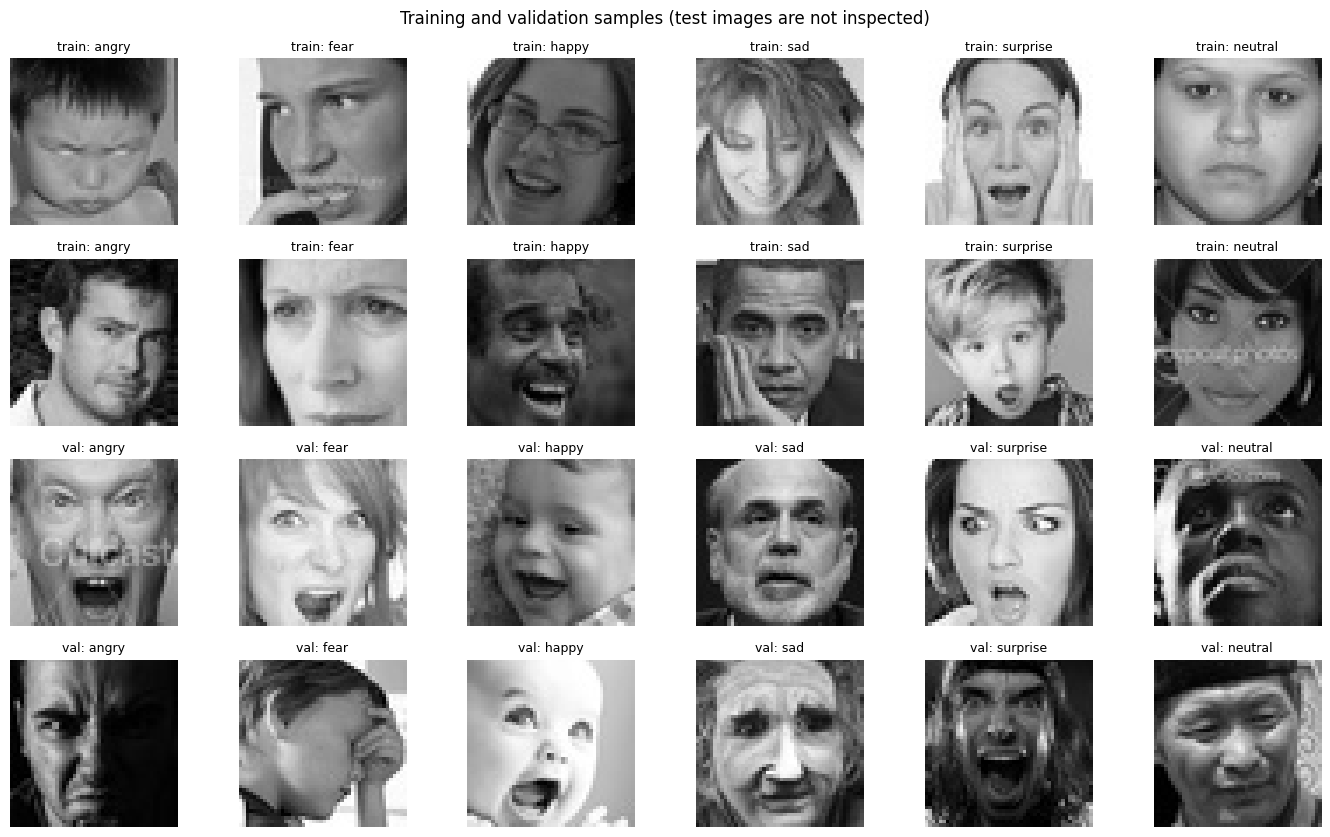

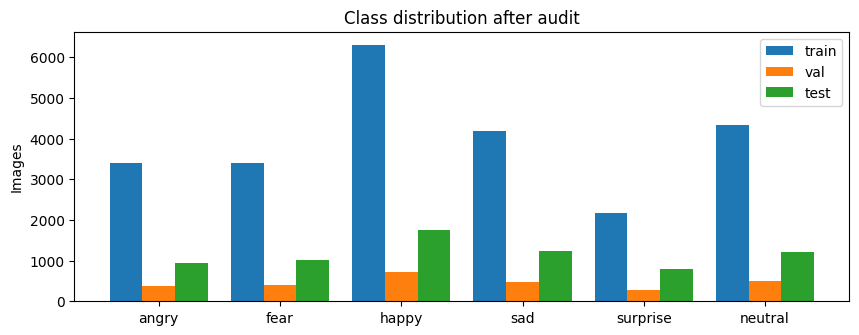

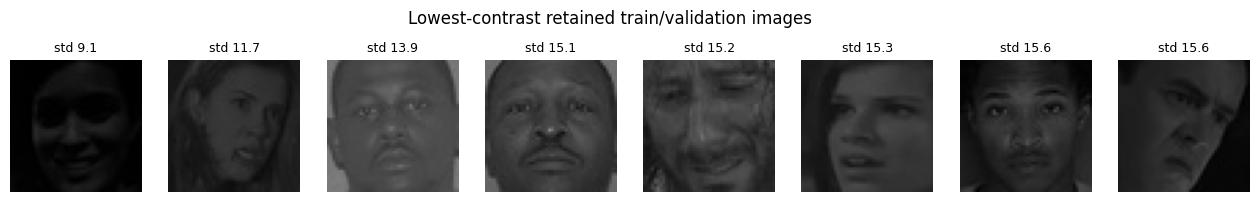

In [ ]:
fig, axes = plt.subplots(4, NUM_CLASSES, figsize=(14, 8.5))
for col, name in enumerate(CLASS_NAMES):
    for row_index, role in enumerate(('train', 'train', 'val', 'val')):
        ax = axes[row_index, col]
        ax.axis('off')
        indices = np.flatnonzero(Y[role] == col)
        if len(indices) > row_index % 2:
            ax.imshow(X[role][indices[row_index % 2]], cmap='gray', vmin=0, vmax=255)
            ax.set_title(f'{role}: {name}', fontsize=9)
fig.suptitle('Training and validation samples (test images are not inspected)')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 3.5))
for i, role in enumerate(ROLES):
    ax.bar(np.arange(NUM_CLASSES) + (i - 1) * 0.27, counts[i], width=0.27, label=role)
ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES)
ax.set_ylabel('Images')
ax.set_title('Class distribution after audit')
ax.legend()
plt.show()


near = sorted((r for r in kept if r['role'] != 'test'), key=lambda r: r['pixel_std'])[:8]
fig, axes = plt.subplots(1, len(near), figsize=(2 * len(near), 2.4), squeeze=False)
for ax, r in zip(axes[0], near):
    ax.imshow(images[r['row']], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'std {r["pixel_std"]:.1f}', fontsize=9)
    ax.axis('off')
fig.suptitle('Lowest-contrast retained train/validation images')
plt.show()


## 5. Shared preprocessing and augmentation checks


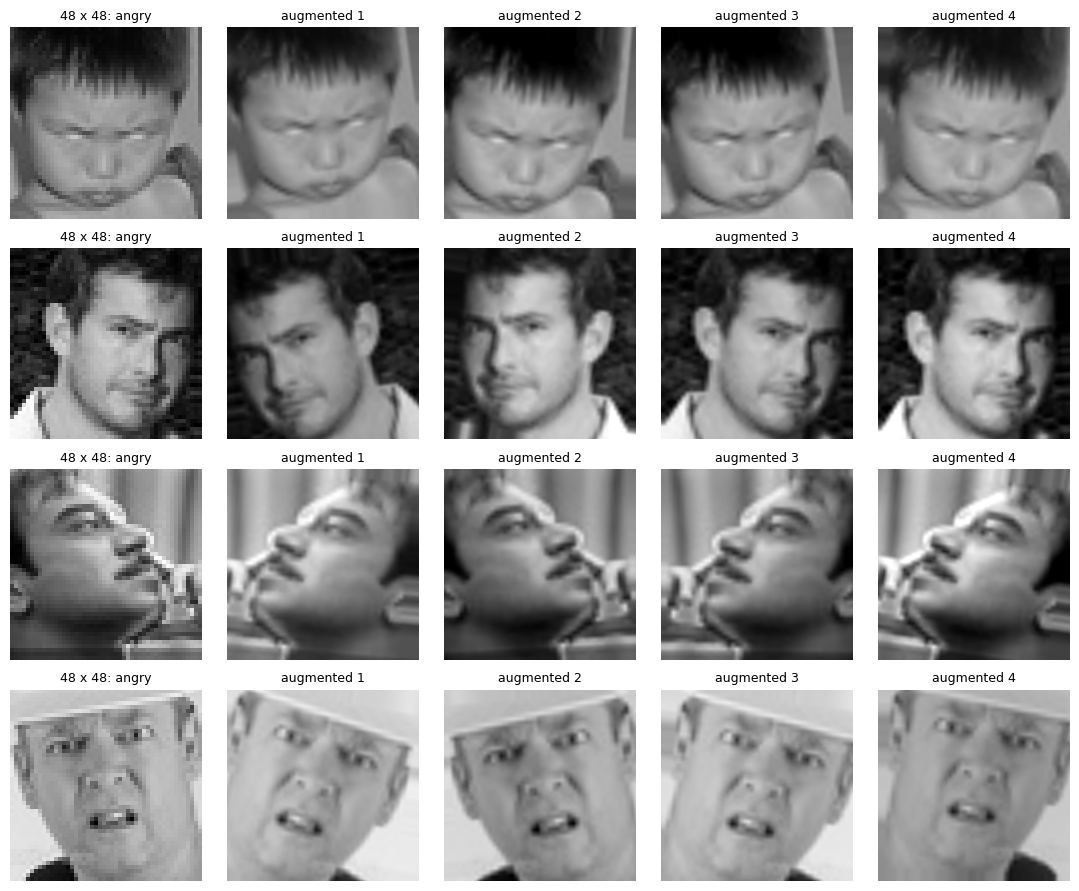

A sharp 192 x 192 crop and its own 48 x 48 downscale give identical model inputs.
Mean absolute difference from the original 48 x 48 face: 2.16 grey levels


In [ ]:
PREPROCESSING = dict(
    input='one RGB uint8 face crop, shape (H, W, 3); convert OpenCV BGR to RGB once in the camera adapter',
    grayscale='cv2.COLOR_RGB2GRAY, replicated to three channels',
    square='symmetric edge-replicated padding (cv2.BORDER_REPLICATE)',
    source_size=SOURCE_SIZE, downscale='cv2.INTER_AREA (cv2.INTER_LINEAR when enlarging)',
    input_size=INPUT_SIZE, upscale='bilinear, align_corners=False', center_crop=False,
    scale='[0, 1]', mean=IMAGENET_MEAN, std=IMAGENET_STD)
MEAN = torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1)
STD = torch.tensor(IMAGENET_STD).view(1, 3, 1, 1)

def face_to_gray48(face):

    assert isinstance(face, np.ndarray) and face.dtype == np.uint8
    assert face.ndim == 2 or (face.ndim == 3 and face.shape[2] == 3), face.shape
    gray = face if face.ndim == 2 else cv2.cvtColor(face, cv2.COLOR_RGB2GRAY)
    height, width = gray.shape
    if height != width:
        pad = abs(height - width)
        before, after = pad // 2, pad - pad // 2
        borders = (before, after, 0, 0) if height < width else (0, 0, before, after)
        gray = cv2.copyMakeBorder(gray, *borders, cv2.BORDER_REPLICATE)
    if gray.shape[0] != SOURCE_SIZE:
        enlarge = gray.shape[0] < SOURCE_SIZE
        gray = cv2.resize(gray, (SOURCE_SIZE, SOURCE_SIZE),
                          interpolation=cv2.INTER_LINEAR if enlarge else cv2.INTER_AREA)
    return gray

def augment_batch(x, generator):

    n = x.shape[0]
    def uniform(low, high):
        return torch.rand(n, device=x.device, generator=generator) * (high - low) + low
    angle = torch.deg2rad(uniform(-AUGMENT['max_rotation_deg'], AUGMENT['max_rotation_deg']))
    flip = torch.where(torch.rand(n, device=x.device, generator=generator) < AUGMENT['flip_p'], -1.0, 1.0)
    shift = 2 * AUGMENT['max_translate']
    tx, ty = uniform(-shift, shift), uniform(-shift, shift)
    cos, sin = torch.cos(angle), torch.sin(angle)
    theta = torch.stack([torch.stack([cos * flip, -sin, tx], 1), torch.stack([sin * flip, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode='bilinear', padding_mode='border', align_corners=False)
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    contrast = uniform(1 - AUGMENT['contrast'], 1 + AUGMENT['contrast']).view(n, 1, 1, 1)
    brightness = uniform(1 - AUGMENT['brightness'], 1 + AUGMENT['brightness']).view(n, 1, 1, 1)
    return (((x - mean) * contrast + mean) * brightness).clamp(0, 1)

def gray48_to_input(batch, augment=False, generator=None):

    x = F.interpolate(batch.float().div(255), size=(INPUT_SIZE, INPUT_SIZE), mode='bilinear', align_corners=False)
    if augment:
        x = augment_batch(x, generator)
    x = x.expand(-1, 3, -1, -1)
    return (x - MEAN.to(x.device)) / STD.to(x.device)

def to_display(x):
    return (x * STD.to(x.device) + MEAN.to(x.device))[:, 0].clamp(0, 1).cpu().numpy()


generator = torch.Generator().manual_seed(SEED)
fig, axes = plt.subplots(4, 5, figsize=(11, 9))
for i in range(4):
    source = torch.from_numpy(X['train'][i:i + 1])[:, None]
    axes[i, 0].imshow(X['train'][i], cmap='gray', vmin=0, vmax=255)
    axes[i, 0].set_title(f'48 x 48: {CLASS_NAMES[Y["train"][i]]}', fontsize=9)
    for j in range(1, 5):
        axes[i, j].imshow(to_display(gray48_to_input(source, augment=True, generator=generator))[0], cmap='gray', vmin=0, vmax=1)
        axes[i, j].set_title(f'augmented {j}', fontsize=9)
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()


face = X['val'][0]
sharp = np.repeat(cv2.resize(face, (192, 192), interpolation=cv2.INTER_CUBIC)[..., None], 3, axis=2)
own_downscale = cv2.resize(cv2.cvtColor(sharp, cv2.COLOR_RGB2GRAY), (48, 48), interpolation=cv2.INTER_AREA)
assert np.array_equal(face_to_gray48(sharp), own_downscale)
assert torch.equal(gray48_to_input(torch.from_numpy(face_to_gray48(sharp))[None, None]),
                   gray48_to_input(torch.from_numpy(face_to_gray48(np.repeat(own_downscale[..., None], 3, 2)))[None, None]))
assert np.array_equal(face_to_gray48(np.repeat(face[..., None], 3, 2)), face), 'A 48 x 48 crop must pass unchanged.'
assert face_to_gray48(np.zeros((120, 90, 3), np.uint8)).shape == (48, 48)
assert face_to_gray48(np.zeros((30, 30, 3), np.uint8)).shape == (48, 48)
assert torch.equal(gray48_to_input(torch.from_numpy(face)[None, None]), gray48_to_input(torch.from_numpy(face)[None, None]))
print('A sharp 192 x 192 crop and its own 48 x 48 downscale give identical model inputs.')
print('Mean absolute difference from the original 48 x 48 face:',
      round(float(np.abs(face_to_gray48(sharp).astype(int) - face).mean()), 2), 'grey levels')


## 6. Model, metrics, and inference utilities


In [ ]:
INIT_WEIGHTS = {'small': 'MobileNet_V3_Small_Weights.IMAGENET1K_V1', 'large': 'MobileNet_V3_Large_Weights.IMAGENET1K_V2'}

def build_model(arch, pretrained=True):
    if arch == 'small':
        model = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1 if pretrained else None)
    elif arch == 'large':
        model = mobilenet_v3_large(weights=MobileNet_V3_Large_Weights.IMAGENET1K_V2 if pretrained else None)
    else:
        raise ValueError(arch)
    model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, NUM_CLASSES)
    return model

def configure_partial_training(model, phase):

    assert phase in {'warmup', 'finetune'}
    frozen_blocks = len(model.features) - UNFREEZE_LAST_BLOCKS
    assert 0 < frozen_blocks < len(model.features), 'Keep at least one frozen and one trainable feature block.'
    model.train()
    for index, block in enumerate(model.features):
        trainable = phase == 'finetune' and index >= frozen_blocks
        block.requires_grad_(trainable)
        if not trainable:
            block.eval()
    model.classifier.requires_grad_(True)
    return frozen_blocks

def class_weights(labels):

    counts = np.bincount(labels, minlength=NUM_CLASSES).astype(float)
    assert counts.min() > 0, 'Every class needs training samples for weighting.'
    weights = np.sqrt(len(labels) / (NUM_CLASSES * counts))
    return weights / weights.mean()

def classification_metrics(labels, predictions):
    labels, predictions = np.asarray(labels), np.asarray(predictions)
    matrix = np.zeros((NUM_CLASSES, NUM_CLASSES), np.int64)
    np.add.at(matrix, (labels, predictions), 1)
    tp = np.diag(matrix).astype(float)
    support, predicted = matrix.sum(1), matrix.sum(0)
    zeros = np.zeros(NUM_CLASSES)
    precision = np.divide(tp, predicted, out=zeros.copy(), where=predicted > 0)
    recall = np.divide(tp, support, out=zeros.copy(), where=support > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=zeros.copy(), where=precision + recall > 0)
    return dict(accuracy=float(tp.sum() / max(matrix.sum(), 1)),
                balanced_accuracy=float(recall[support > 0].mean()) if (support > 0).any() else 0.0,
                macro_precision=float(precision.mean()), macro_recall=float(recall.mean()),
                macro_f1=float(f1.mean()), weighted_f1=float((f1 * support).sum() / max(support.sum(), 1)),
                per_class={name: dict(precision=float(precision[i]), recall=float(recall[i]), f1=float(f1[i]),
                                      support=int(support[i])) for i, name in enumerate(CLASS_NAMES)},
                confusion_matrix=matrix.tolist())

def cross_entropy(probabilities, labels):
    return float(-np.log(np.clip(probabilities[np.arange(len(labels)), labels], 1e-12, 1)).mean())

@torch.no_grad()
def predict_probabilities(model, gray48_images, batch=256):
    model.eval()
    device = next(model.parameters()).device
    outputs = []
    for start in range(0, len(gray48_images), batch):
        x = gray48_to_input(torch.from_numpy(gray48_images[start:start + batch])[:, None].to(device))
        with torch.autocast(device.type, enabled=device.type == 'cuda'):
            logits = model(x)
        outputs.append(logits.float().softmax(1).cpu())
    return torch.cat(outputs).numpy()

def atomic_save(obj, path):
    temporary = path.with_suffix('.tmp')
    torch.save(obj, temporary)
    os.replace(temporary, path)

def checkpoint_payload(model, arch, **extra):
    return dict(format='emotion-mobilenetv3-v1', arch=arch, num_classes=NUM_CLASSES, class_names=CLASS_NAMES,
                preprocessing=PREPROCESSING,
                state_dict={k: v.detach().cpu() for k, v in model.state_dict().items()}, **extra)

def load_checkpoint(path):
    payload = torch.load(path, map_location='cpu', weights_only=True)
    assert payload['format'] == 'emotion-mobilenetv3-v1' and payload['class_names'] == CLASS_NAMES
    assert payload['num_classes'] == NUM_CLASSES, 'Expected a six-class checkpoint without disgust.'
    assert payload['preprocessing'] == PREPROCESSING, 'Checkpoint was trained with different preprocessing.'
    return payload

class EmotionClassifier:


    def __init__(self, checkpoint_path, device='cpu', threshold=None):
        payload = load_checkpoint(checkpoint_path)
        self.device = torch.device(device)
        self.model = build_model(payload['arch'], pretrained=False)
        self.model.load_state_dict(payload['state_dict'])
        self.model.to(self.device).eval()
        self.class_names = payload['class_names']
        self.threshold = payload.get('display_threshold') if threshold is None else threshold

    @torch.inference_mode()
    def predict_emotions(self, face_crops_rgb):

        results, valid = [None] * len(face_crops_rgb), []
        for i, face in enumerate(face_crops_rgb):
            usable = (isinstance(face, np.ndarray) and face.dtype == np.uint8 and face.ndim == 3
                      and face.shape[2] == 3 and min(face.shape[:2]) >= MIN_CROP_SIDE)
            if usable:
                valid.append(i)
            else:
                results[i] = dict(label=None, confidence=None, probabilities=None, status='unavailable')
        if valid:
            batch = torch.from_numpy(np.stack([face_to_gray48(face_crops_rgb[i]) for i in valid]))[:, None]
            probabilities = self.model(gray48_to_input(batch.to(self.device))).float().softmax(1).cpu().numpy()
            for i, p in zip(valid, probabilities):
                k = int(p.argmax())
                confidence = float(p[k])

                ok = self.threshold is not None and confidence >= self.threshold
                results[i] = dict(label=self.class_names[k], confidence=confidence,
                                  probabilities=[float(v) for v in p], status='ok' if ok else 'uncertain')
        return results

def measure_latency(classifier, faces, repeats=30, warmup=5):

    rng = np.random.default_rng(SEED)
    crops = [rng.integers(0, 256, (160, 140, 3), dtype=np.uint8) for _ in range(faces)]
    sync = torch.cuda.synchronize if classifier.device.type == 'cuda' else (lambda: None)
    for _ in range(warmup):
        classifier.predict_emotions(crops)
    times = []
    for _ in range(repeats):
        sync()
        started = time.perf_counter()
        classifier.predict_emotions(crops)
        sync()
        times.append((time.perf_counter() - started) * 1000)
    return dict(device=classifier.device.type, faces=faces, p50_ms=round(float(np.percentile(times, 50)), 2),
                p95_ms=round(float(np.percentile(times, 95)), 2))


In [ ]:
def run_experiment(name, arch, weighted, train, val, out_dir, warmup_epochs, finetune_epochs):

    out_dir.mkdir(parents=True, exist_ok=True)
    config = dict(name=name, arch=arch, init_weights=INIT_WEIGHTS[arch], weighted_loss=bool(weighted), seed=SEED,
                  finetuning='partial', unfreeze_last_blocks=UNFREEZE_LAST_BLOCKS, label_smoothing=0.05,
                  class_names=CLASS_NAMES, source_to_model_id=SOURCE_TO_MODEL_ID, excluded_classes=['disgust'],
                  batch=BATCH, warmup_epochs=warmup_epochs, finetune_epochs=finetune_epochs, head_lr=HEAD_LR,
                  backbone_lr=BACKBONE_LR, classifier_lr=CLASSIFIER_LR, weight_decay=WEIGHT_DECAY,
                  plateau_patience=PLATEAU_PATIENCE, plateau_factor=PLATEAU_FACTOR,
                  early_stop_patience=EARLY_STOP_PATIENCE, min_delta=MIN_DELTA, augment=AUGMENT,
                  amp=DEVICE.type == 'cuda', train_size=len(train[1]), val_size=len(val[1]),
                  train_rows_sha256=hashlib.sha256(train[2].tobytes()).hexdigest(),
                  val_rows_sha256=hashlib.sha256(val[2].tobytes()).hexdigest())
    config = json.loads(json.dumps(config))
    done, last, best_path = out_dir / 'done.json', out_dir / 'last.pt', out_dir / 'best.pt'
    if done.exists():
        summary = json.loads(done.read_text())
        assert summary['config'] == config, f'{out_dir} holds a different configuration; move it before retraining.'
        print(f'{name}: reusing completed run (best epoch {summary["best_epoch"]}).')
        return summary

    seed_everything(SEED)
    model = build_model(arch).to(DEVICE)
    frozen_blocks = len(model.features) - UNFREEZE_LAST_BLOCKS
    assert 0 < frozen_blocks < len(model.features), 'UNFREEZE_LAST_BLOCKS must leave some feature blocks frozen.'
    trainable_key = next(k for k, _ in model.features.named_parameters()
                         if int(k.split('.')[0]) >= frozen_blocks)
    loss_weights = class_weights(train[1]) if weighted else np.ones(NUM_CLASSES)
    criterion = nn.CrossEntropyLoss(   weight=torch.tensor(loss_weights, dtype=torch.float32, device=DEVICE),
    label_smoothing=0.05,)
    train_x = torch.from_numpy(train[0])[:, None].to(DEVICE)
    train_y = torch.from_numpy(train[1]).to(DEVICE)
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=DEVICE.type == 'cuda')

    def make_phase(phase):
        finetune = phase == 'finetune'
        configure_partial_training(model, phase)
        groups = ([{'params': [p for p in model.features.parameters() if p.requires_grad], 'lr': BACKBONE_LR},
                   {'params': model.classifier.parameters(), 'lr': CLASSIFIER_LR}] if finetune
                  else [{'params': model.classifier.parameters(), 'lr': HEAD_LR}])
        optimizer = torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)
        scheduler = (torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=PLATEAU_FACTOR,
                                                                patience=PLATEAU_PATIENCE) if finetune else None)
        return optimizer, scheduler

    phase = 'warmup' if warmup_epochs else 'finetune'
    optimizer, scheduler = make_phase(phase)
    state = dict(epoch=0, history=[], best=None, best_for_stop=-1.0, bad_epochs=0, stopped=False,
                 train_seconds=0.0,
                 frozen_reference={k: v.detach().cpu().clone() for k, v in model.features.state_dict().items()
                                   if int(k.split('.')[0]) < frozen_blocks},
                 backbone_reference=model.features.state_dict()[trainable_key].detach().cpu().clone())
    if last.exists():
        saved = torch.load(last, map_location=DEVICE, weights_only=True)
        assert saved['config'] == config, f'{last} belongs to a different configuration; move it before retraining.'
        model.load_state_dict(saved['model'])
        phase = saved['phase']
        optimizer, scheduler = make_phase(phase)
        optimizer.load_state_dict(saved['optimizer'])
        if scheduler is not None:
            scheduler.load_state_dict(saved['scheduler'])
        scaler.load_state_dict(saved['scaler'])
        state = saved['state']
        print(f'{name}: resuming after epoch {state["epoch"]}.')

    if DEVICE.type == 'cuda':
        torch.cuda.reset_peak_memory_stats()
    total_epochs = warmup_epochs + finetune_epochs
    while state['epoch'] < total_epochs and not state['stopped']:
        epoch = state['epoch']
        wanted = 'warmup' if epoch < warmup_epochs else 'finetune'
        if wanted != phase:
            phase = wanted
            optimizer, scheduler = make_phase(phase)
        seed_everything(SEED + epoch)
        generator = torch.Generator(device=DEVICE).manual_seed(SEED + epoch)
        configure_partial_training(model, phase)
        started = time.time()
        order = torch.randperm(len(train_y), generator=generator, device=DEVICE)
        loss_sum, seen = 0.0, 0

        for start in range(0, len(order) - 1, BATCH):
            index = order[start:start + BATCH]
            x = gray48_to_input(train_x[index], augment=True, generator=generator)
            with torch.autocast(DEVICE.type, enabled=DEVICE.type == 'cuda'):
                loss = criterion(model(x), train_y[index])
            assert torch.isfinite(loss), f'{name}: non-finite loss at epoch {epoch + 1}'
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            loss_sum += loss.item() * len(index)
            seen += len(index)

        probabilities = predict_probabilities(model, val[0])
        metrics = classification_metrics(val[1], probabilities.argmax(1))
        val_loss = cross_entropy(probabilities, val[1])
        seconds = time.time() - started
        state['train_seconds'] += seconds
        state['history'].append(dict(epoch=epoch + 1, phase=phase, train_loss=loss_sum / seen, val_loss=val_loss,
                                     val_macro_f1=metrics['macro_f1'], val_accuracy=metrics['accuracy'],
                                     lrs=[g['lr'] for g in optimizer.param_groups], seconds=round(seconds, 1)))
        print(f'{name} epoch {epoch + 1:>2}/{total_epochs} [{phase}] train loss {loss_sum / seen:.4f} | '
              f'val loss {val_loss:.4f} | val macro-F1 {metrics["macro_f1"]:.4f} | val acc {metrics["accuracy"]:.4f} | {seconds:.0f}s')
        if phase == 'finetune':

            score = [round(metrics['macro_f1'], 6), -round(val_loss, 6)]
            if state['best'] is None or score > state['best']['score']:
                state['best'] = dict(score=score, epoch=epoch + 1, val_metrics=metrics, val_loss=val_loss)
                atomic_save(checkpoint_payload(model, arch, experiment=name, epoch=epoch + 1, config=config,
                                               val_metrics=metrics, val_loss=val_loss), best_path)
            if metrics['macro_f1'] > state['best_for_stop'] + MIN_DELTA:
                state['best_for_stop'], state['bad_epochs'] = metrics['macro_f1'], 0
            else:
                state['bad_epochs'] += 1
            scheduler.step(metrics['macro_f1'])
            state['stopped'] = state['bad_epochs'] >= EARLY_STOP_PATIENCE
            if state['stopped']:
                print(f'{name}: early stopping after epoch {epoch + 1}.')
        state['epoch'] = epoch + 1
        atomic_save(dict(config=config, phase=phase, model=model.state_dict(), optimizer=optimizer.state_dict(),
                         scheduler=scheduler.state_dict() if scheduler is not None else None,
                         scaler=scaler.state_dict(), state=state), last)

    assert state['best'] is not None, f'{name}: no fine-tuning epoch completed.'
    best = load_checkpoint(best_path)
    for key, reference in state['frozen_reference'].items():
        assert torch.equal(model.features.state_dict()[key].cpu(), reference.cpu()), f'{name}: frozen tensor changed: {key}'
        assert torch.equal(best['state_dict']['features.' + key].cpu(), reference.cpu()), f'{name}: frozen best tensor changed: {key}'
    backbone_change = float((best['state_dict']['features.' + trainable_key].cpu() - state['backbone_reference'].cpu()).abs().max())
    assert backbone_change > 0, f'{name}: trainable backbone weights did not change during partial fine-tuning.'
    reloaded = build_model(arch, pretrained=False)
    reloaded.load_state_dict(best['state_dict'])
    reloaded_f1 = classification_metrics(val[1], predict_probabilities(reloaded.to(DEVICE), val[0]).argmax(1))['macro_f1']
    assert abs(reloaded_f1 - state['best']['val_metrics']['macro_f1']) < 1e-4, 'Reloaded checkpoint disagrees with training.'

    summary = dict(config=config, best_epoch=state['best']['epoch'], val_metrics=state['best']['val_metrics'],
                   val_loss=state['best']['val_loss'], epochs_run=state['epoch'], early_stopped=state['stopped'],
                   train_minutes=round(state['train_seconds'] / 60, 1),
                   peak_gpu_gib_this_session=round(torch.cuda.max_memory_allocated() / 2**30, 2) if DEVICE.type == 'cuda' else None,
                   parameters=sum(p.numel() for p in model.parameters()),
                   trainable_parameters=sum(p.numel() for p in model.parameters() if p.requires_grad),
                   frozen_feature_blocks=frozen_blocks, frozen_max_abs_change=0.0,
                   backbone_max_abs_change=backbone_change,
                   class_weights=[float(w) for w in loss_weights], history=state['history'])
    done.write_text(json.dumps(summary, indent=2))

    history = state['history']
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    epochs = [h['epoch'] for h in history]
    axes[0].plot(epochs, [h['train_loss'] for h in history], label='train (weighted)' if weighted else 'train (unweighted)')
    axes[0].plot(epochs, [h['val_loss'] for h in history], label='validation (unweighted)')
    axes[1].plot(epochs, [h['val_macro_f1'] for h in history], label='validation macro-F1')
    axes[1].plot(epochs, [h['val_accuracy'] for h in history], label='validation accuracy')
    for ax, ylabel in zip(axes, ('Cross-entropy', 'Score')):
        if warmup_epochs:
            ax.axvline(warmup_epochs + 0.5, color='grey', linestyle='--', linewidth=1)
        ax.axvline(summary['best_epoch'], color='green', linestyle=':', linewidth=1)
        ax.set_xlabel('Epoch')
        ax.set_ylabel(ylabel)
        ax.legend()
    fig.suptitle(f'{name}: {arch}, {"weighted" if weighted else "unweighted"} loss (dashed: end of warm-up, dotted: selected epoch)')
    plt.tight_layout()
    fig.savefig(out_dir / 'curves.png', dpi=120)
    plt.show()
    print(f'{name}: best epoch {summary["best_epoch"]}, validation macro-F1 {summary["val_metrics"]["macro_f1"]:.4f}, '
          f'{summary["train_minutes"]} training minutes, trainable backbone max change {backbone_change:.2e}; '
          f'feature blocks 0-{frozen_blocks - 1} unchanged (including BatchNorm buffers).')
    return summary


## 7. Smoke run or partial fine-tuning


Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 62.3MB/s]


E5 epoch  1/28 [warmup] train loss 1.4972 | val loss 1.3671 | val macro-F1 0.4596 | val acc 0.4739 | 13s
E5 epoch  2/28 [warmup] train loss 1.3941 | val loss 1.3339 | val macro-F1 0.4410 | val acc 0.4800 | 13s
E5 epoch  3/28 [warmup] train loss 1.3503 | val loss 1.3265 | val macro-F1 0.4523 | val acc 0.4808 | 13s
E5 epoch  4/28 [finetune] train loss 1.3408 | val loss 1.1415 | val macro-F1 0.5421 | val acc 0.5679 | 21s
E5 epoch  5/28 [finetune] train loss 1.1116 | val loss 1.0149 | val macro-F1 0.5966 | val acc 0.6216 | 21s
E5 epoch  6/28 [finetune] train loss 1.0108 | val loss 1.0172 | val macro-F1 0.5994 | val acc 0.6235 | 20s
E5 epoch  7/28 [finetune] train loss 0.9308 | val loss 0.9985 | val macro-F1 0.6199 | val acc 0.6387 | 20s
E5 epoch  8/28 [finetune] train loss 0.8476 | val loss 0.9924 | val macro-F1 0.6187 | val acc 0.6351 | 20s
E5 epoch  9/28 [finetune] train loss 0.7768 | val loss 1.0181 | val macro-F1 0.6119 | val acc 0.6322 | 20s
E5 epoch 10/28 [finetune] train loss 0.7078

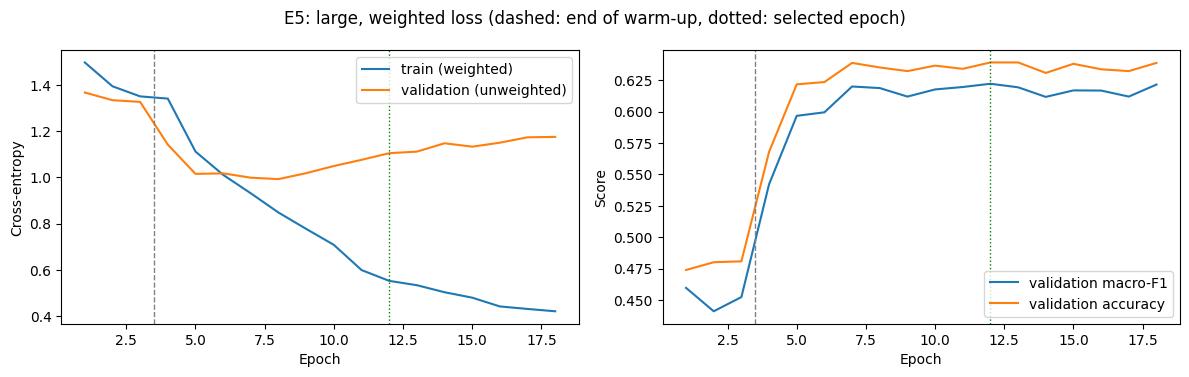

E5: best epoch 12, validation macro-F1 0.6221, 5.7 training minutes, trainable backbone max change 3.15e-02; feature blocks 0-10 unchanged (including BatchNorm buffers).


In [ ]:
def take_per_class(labels, per_class, seed):
    rng = np.random.default_rng(seed)
    return np.sort(np.concatenate([rng.permutation(np.flatnonzero(labels == c))[:per_class] for c in range(NUM_CLASSES)]))

TRAIN = (X['train'], Y['train'], ROWS['train'])
VAL = (X['val'], Y['val'], ROWS['val'])
results = {}
if RUN_MODE == 'smoke':
    smoke_dir = PERSIST / 'smoke'
    shutil.rmtree(smoke_dir, ignore_errors=True)
    t, v = take_per_class(Y['train'], SMOKE_TRAIN_PER_CLASS, SEED), take_per_class(Y['val'], SMOKE_VAL_PER_CLASS, SEED)
    results['smoke'] = run_experiment('smoke', 'small', False, tuple(a[t] for a in TRAIN), tuple(a[v] for a in VAL),
                                      smoke_dir, warmup_epochs=1, finetune_epochs=1)
    SELECTED = dict(name='smoke', checkpoint=str(smoke_dir / 'best.pt'))
elif RUN_MODE == 'train':
    assert DEVICE.type == 'cuda', 'Select a GPU runtime for full training.'
    if COMPARE_SMALL_MODELS:
        for name in ('E1', 'E2'):
            spec = EXPERIMENTS[name]
            results[name] = run_experiment(name, spec['arch'], spec['weighted'], TRAIN, VAL, PERSIST / 'runs' / name,
                                           WARMUP_EPOCHS, FINETUNE_EPOCHS)

        SMALL_WINNER = max(('E1', 'E2'), key=lambda n: (round(results[n]['val_metrics']['macro_f1'], 6),
                                                        -round(results[n]['val_loss'], 6)))
        print('Small-model loss chosen on validation:', SMALL_WINNER)
        results['E3'] = run_experiment('E3', 'large', EXPERIMENTS[SMALL_WINNER]['weighted'], TRAIN, VAL,
                                       PERSIST / 'runs' / 'E3', WARMUP_EPOCHS, FINETUNE_EPOCHS)
    else:
        results['E5'] = run_experiment('E5', 'large', True, TRAIN, VAL, PERSIST / 'runs' / 'E5',
                                       WARMUP_EPOCHS, FINETUNE_EPOCHS)
else:
    for name in (EXPERIMENTS if COMPARE_SMALL_MODELS else ('E5',)):
        done = PERSIST / 'runs' / name / 'done.json'
        if done.exists():
            results[name] = json.loads(done.read_text())
    print('Loaded completed runs:', list(results))


## 8. Validation comparison, model choice, and confidence threshold


run  arch   weighted  epoch  macro-F1     acc  bal.acc  val CE     params   CPU p95
E5   large  True         12    0.6221  0.6391   0.6236  1.1045  4,209,718    28.1ms
Rule: Large with E3 weighted loss, best epoch by validation macro-F1
Selected model: E5 | /content/drive/MyDrive/emotion_mobilenetv3_6class_partial_last6_ls005/runs/E5/best.pt
Display threshold 0.80: validation coverage 49.7%, accepted accuracy 80.4%
Class-wise validation coverage: {'angry': 0.444, 'fear': 0.39, 'happy': 0.642, 'sad': 0.43, 'surprise': 0.575, 'neutral': 0.436}


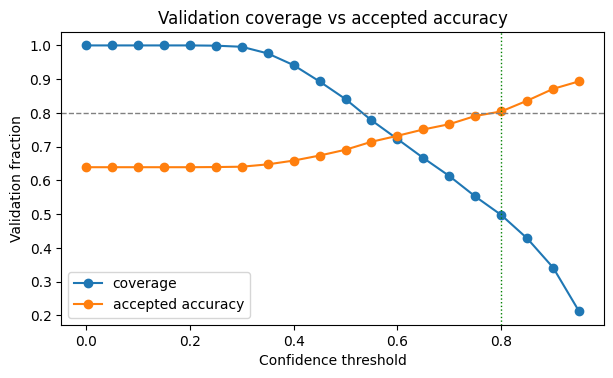

In [ ]:
if RUN_MODE == 'train':
    comparison = []
    for name, summary in results.items():
        latency = measure_latency(EmotionClassifier(PERSIST / 'runs' / name / 'best.pt', 'cpu'), faces=1)
        comparison.append(dict(name=name, arch=summary['config']['arch'], weighted_loss=summary['config']['weighted_loss'],
                               best_epoch=summary['best_epoch'], val_macro_f1=summary['val_metrics']['macro_f1'],
                               val_accuracy=summary['val_metrics']['accuracy'],
                               val_balanced_accuracy=summary['val_metrics']['balanced_accuracy'],
                               val_loss=summary['val_loss'], parameters=summary['parameters'],
                               train_minutes=summary['train_minutes'], cpu_p95_ms_one_face=latency['p95_ms']))
    if COMPARE_SMALL_MODELS:
        rows = {row['name']: row for row in comparison}
        large_selected = (rows['E3']['val_macro_f1'] >= rows[SMALL_WINNER]['val_macro_f1'] + LARGE_MARGIN
                          and rows['E3']['cpu_p95_ms_one_face'] <= CPU_P95_BUDGET_MS)
        chosen = 'E3' if large_selected else SMALL_WINNER
        SELECTED = dict(name=chosen, checkpoint=str(PERSIST / 'runs' / chosen / 'best.pt'), small_winner=SMALL_WINNER,
                        rule=f'E3 if validation macro-F1 >= {SMALL_WINNER} + {LARGE_MARGIN} and CPU p95 <= {CPU_P95_BUDGET_MS} ms; otherwise {SMALL_WINNER}',
                        comparison=comparison, latency_note='Colab CPU latency is a proxy; re-measure on the demonstration laptop.')
    else:
        SELECTED = dict(name='E5', checkpoint=str(PERSIST / 'runs' / 'E5' / 'best.pt'),
                        rule='Large with E3 weighted loss, best epoch by validation macro-F1', comparison=comparison)
    (PERSIST / 'selection.json').write_text(json.dumps(SELECTED, indent=2))
elif RUN_MODE == 'evaluate':
    SELECTED = json.loads((PERSIST / 'selection.json').read_text())

if SELECTED.get('comparison'):
    print(f'{"run":<4} {"arch":<6} {"weighted":<9} {"epoch":>5} {"macro-F1":>9} {"acc":>7} {"bal.acc":>8} {"val CE":>7} {"params":>10} {"CPU p95":>9}')
    for row in SELECTED['comparison']:
        print(f'{row["name"]:<4} {row["arch"]:<6} {str(row["weighted_loss"]):<9} {row["best_epoch"]:>5} '
              f'{row["val_macro_f1"]:>9.4f} {row["val_accuracy"]:>7.4f} {row["val_balanced_accuracy"]:>8.4f} '
              f'{row["val_loss"]:>7.4f} {row["parameters"]:>10,} {row["cpu_p95_ms_one_face"]:>7.1f}ms')
    print('Rule:', SELECTED['rule'])
print('Selected model:', SELECTED['name'], '|', SELECTED['checkpoint'])

selected_model = EmotionClassifier(SELECTED['checkpoint'], DEVICE)
val_probabilities = predict_probabilities(selected_model.model, X['val'])
val_metrics = classification_metrics(Y['val'], val_probabilities.argmax(1))

def threshold_table(probabilities, labels):
    confidence, correct = probabilities.max(1), probabilities.argmax(1) == labels
    table = []
    for threshold in THRESHOLDS:
        accepted = confidence >= threshold
        table.append(dict(threshold=threshold, coverage=float(accepted.mean()),
                          accepted_accuracy=float(correct[accepted].mean()) if accepted.any() else None,
                          class_coverage={CLASS_NAMES[c]: float(accepted[labels == c].mean()) for c in range(NUM_CLASSES)
                                          if (labels == c).any()}))
    return table

val_thresholds = threshold_table(val_probabilities, Y['val'])
qualifying = [r for r in val_thresholds if r['accepted_accuracy'] is not None
              and r['accepted_accuracy'] >= TARGET_ACCEPTED_ACCURACY]
chosen_row = max(qualifying, key=lambda r: (r['coverage'], -r['threshold'])) if qualifying else None
DISPLAY_THRESHOLD = chosen_row['threshold'] if chosen_row else None
threshold_report = dict(target_accepted_accuracy=TARGET_ACCEPTED_ACCURACY, display_threshold=DISPLAY_THRESHOLD,
                        validation=chosen_row, validation_table=val_thresholds)
if DISPLAY_THRESHOLD is None:
    print(f'No threshold reaches {TARGET_ACCEPTED_ACCURACY:.0%} accepted validation accuracy: '
          'confident-status display is disabled and every prediction is shown as uncertain.')
else:
    print(f'Display threshold {DISPLAY_THRESHOLD:.2f}: validation coverage {chosen_row["coverage"]:.1%}, '
          f'accepted accuracy {chosen_row["accepted_accuracy"]:.1%}')
    print('Class-wise validation coverage:', {k: round(v, 3) for k, v in chosen_row['class_coverage'].items()})

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(THRESHOLDS, [r['coverage'] for r in val_thresholds], marker='o', label='coverage')
ax.plot(THRESHOLDS, [r['accepted_accuracy'] if r['accepted_accuracy'] is not None else np.nan for r in val_thresholds],
        marker='o', label='accepted accuracy')
ax.axhline(TARGET_ACCEPTED_ACCURACY, color='grey', linestyle='--', linewidth=1)
if DISPLAY_THRESHOLD is not None:
    ax.axvline(DISPLAY_THRESHOLD, color='green', linestyle=':', linewidth=1)
ax.set_xlabel('Confidence threshold')
ax.set_ylabel('Validation fraction')
ax.set_title('Validation coverage vs accepted accuracy')
ax.legend()
plt.show()


## 9. Frozen test evaluation and error analysis


Test (folder-based FER2013 protocol (audited), n=6957): macro-F1 0.6258 | accuracy 0.6428 | balanced accuracy 0.6276 | macro precision 0.6258 | macro recall 0.6276 | weighted-F1 0.6431
class      precision  recall      F1  support
angry          0.534   0.581   0.557      941
fear           0.504   0.432   0.465     1005
happy          0.876   0.836   0.855     1764
sad            0.520   0.528   0.524     1235
surprise       0.748   0.768   0.758      788
neutral        0.573   0.621   0.596     1224
At display threshold 0.80: test coverage 50.2%, accepted accuracy 82.2% (not full-dataset accuracy; the validation target is not guaranteed on test)


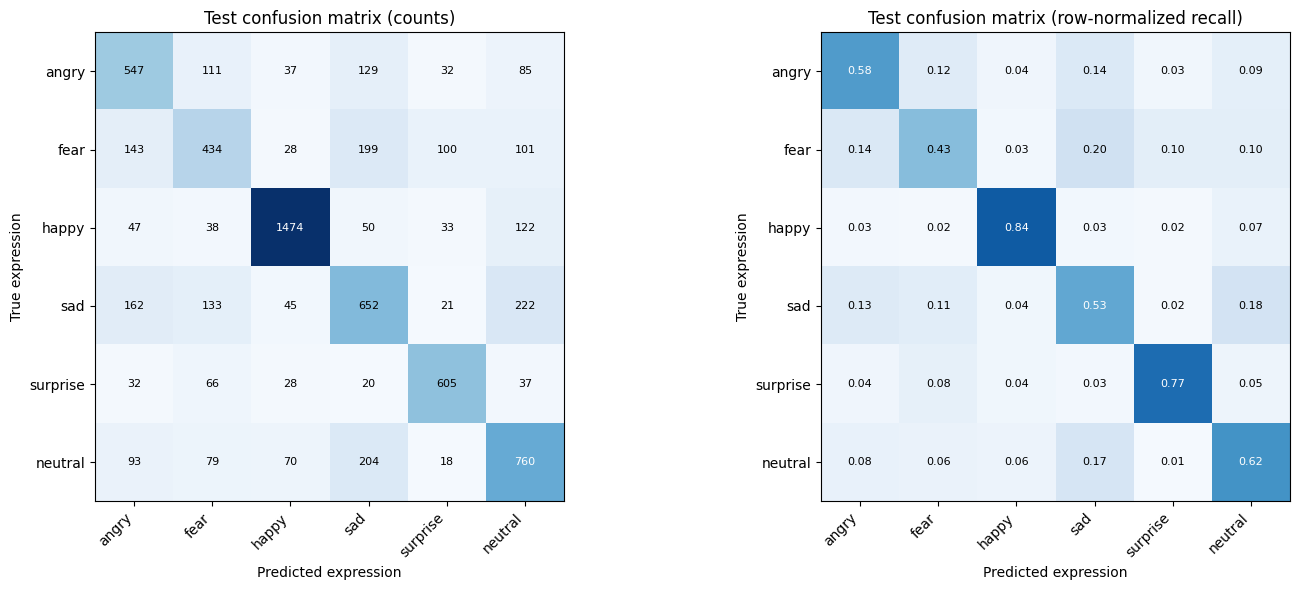

Most frequent confusions (true -> predicted): [('sad -> neutral', 222), ('neutral -> sad', 204), ('fear -> sad', 199), ('sad -> angry', 162), ('fear -> angry', 143), ('sad -> fear', 133)]


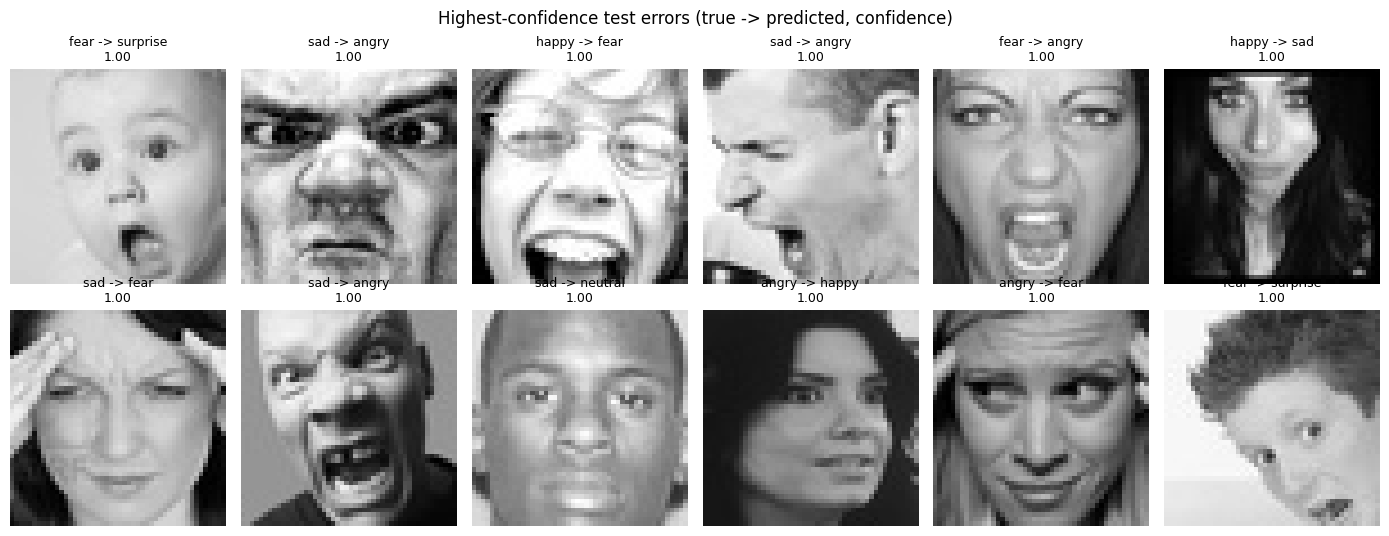

In [ ]:
def plot_confusion(matrix, ax, normalize, title):
    m = np.asarray(matrix, float)
    if normalize:
        totals = m.sum(1, keepdims=True)
        m = np.divide(m, totals, out=np.zeros_like(m), where=totals > 0)
    ax.imshow(m, cmap='Blues', vmin=0, vmax=1 if normalize else None)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, f'{m[i, j]:.2f}' if normalize else int(m[i, j]), ha='center', va='center', fontsize=8,
                    color='white' if m[i, j] > (0.5 if normalize else m.max() / 2) else 'black')
    ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha='right')
    ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
    ax.set_xlabel('Predicted expression')
    ax.set_ylabel('True expression')
    ax.set_title(title)

if RUN_MODE == 'smoke':
    test_report = None
    print('Smoke mode: the held-out test set is not used.')
else:
    test_probabilities = predict_probabilities(selected_model.model, X['test'])
    test_predictions = test_probabilities.argmax(1)
    test_metrics = classification_metrics(Y['test'], test_predictions)
    test_table = {r['threshold']: r for r in threshold_table(test_probabilities, Y['test'])}
    test_report = dict(protocol=PROTOCOL_NAME, selected=SELECTED['name'], checkpoint=SELECTED['checkpoint'],
                       checkpoint_sha256=sha256_file(SELECTED['checkpoint']), test_size=int(len(Y['test'])),
                       exclusions=dict(exclusions), metrics=test_metrics, validation_metrics=val_metrics,
                       display_threshold=DISPLAY_THRESHOLD,
                       test_at_display_threshold=test_table.get(DISPLAY_THRESHOLD),
                       note='Single-seed result; confidence is a maximum softmax score, not a calibrated probability.')
    (PERSIST / 'test_metrics.json').write_text(json.dumps(test_report, indent=2))

    print(f'Test ({PROTOCOL_NAME}, n={len(Y["test"])}): macro-F1 {test_metrics["macro_f1"]:.4f} | '
          f'accuracy {test_metrics["accuracy"]:.4f} | balanced accuracy {test_metrics["balanced_accuracy"]:.4f} | '
          f'macro precision {test_metrics["macro_precision"]:.4f} | macro recall {test_metrics["macro_recall"]:.4f} | '
          f'weighted-F1 {test_metrics["weighted_f1"]:.4f}')
    print(f'{"class":<10}{"precision":>10}{"recall":>8}{"F1":>8}{"support":>9}')
    for name, m in test_metrics['per_class'].items():
        print(f'{name:<10}{m["precision"]:>10.3f}{m["recall"]:>8.3f}{m["f1"]:>8.3f}{m["support"]:>9}')
    if DISPLAY_THRESHOLD is not None:
        row = test_table[DISPLAY_THRESHOLD]
        accepted = 'n/a' if row['accepted_accuracy'] is None else f'{row["accepted_accuracy"]:.1%}'
        print(f'At display threshold {DISPLAY_THRESHOLD:.2f}: test coverage {row["coverage"]:.1%}, accepted accuracy '
              f'{accepted} (not full-dataset accuracy; the validation target is not guaranteed on test)')

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    plot_confusion(test_metrics['confusion_matrix'], axes[0], False, 'Test confusion matrix (counts)')
    plot_confusion(test_metrics['confusion_matrix'], axes[1], True, 'Test confusion matrix (row-normalized recall)')
    plt.tight_layout()
    fig.savefig(PERSIST / 'confusion_matrices.png', dpi=120)
    plt.show()

    matrix = np.array(test_metrics['confusion_matrix'])
    pairs = sorted(((matrix[i, j], CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(NUM_CLASSES)
                    for j in range(NUM_CLASSES) if i != j), reverse=True)[:6]
    print('Most frequent confusions (true -> predicted):', [(f'{a} -> {b}', int(n)) for n, a, b in pairs])

    wrong = np.flatnonzero(test_predictions != Y['test'])
    wrong = wrong[np.argsort(-test_probabilities[wrong].max(1))][:12]
    fig, axes = plt.subplots(2, 6, figsize=(14, 5.5), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, i in zip(axes.flat, wrong):
        ax.imshow(X['test'][i], cmap='gray', vmin=0, vmax=255)
        ax.set_title(f'{CLASS_NAMES[Y["test"][i]]} -> {CLASS_NAMES[test_predictions[i]]}\n'
                     f'{test_probabilities[i].max():.2f}', fontsize=9)
    fig.suptitle('Highest-confidence test errors (true -> predicted, confidence)')
    plt.tight_layout()
    fig.savefig(PERSIST / 'test_errors.png', dpi=120)
    plt.show()


## 10. Crop-level inference, contract checks, and latency


In [ ]:
classifier = EmotionClassifier(SELECTED['checkpoint'], 'cpu', threshold=DISPLAY_THRESHOLD)
sample_crops = [np.repeat(X['val'][i][..., None], 3, axis=2) for i in range(min(64, len(X['val'])))]
outputs = classifier.predict_emotions(sample_crops)
assert classifier.predict_emotions([]) == []
assert len(outputs) == len(sample_crops)
for result in outputs:
    assert result['status'] in {'ok', 'uncertain'} and result['label'] in CLASS_NAMES
    assert len(result['probabilities']) == NUM_CLASSES and np.isfinite(result['probabilities']).all()
    assert abs(sum(result['probabilities']) - 1) < 1e-4 and result['confidence'] == max(result['probabilities'])
mixed = classifier.predict_emotions([sample_crops[0], np.zeros((8, 8, 3), np.uint8), np.zeros((0, 0, 3), np.uint8),
                                     None, sample_crops[0].astype(np.float32), sample_crops[1]])
assert [r['status'] == 'unavailable' for r in mixed] == [False, True, True, True, True, False]
assert mixed[0]['label'] == outputs[0]['label'] and mixed[5]['label'] == outputs[1]['label'], 'Input order was not preserved.'
cpu_labels = np.array([CLASS_NAMES.index(r['label']) for r in outputs])
device_labels = val_probabilities[:len(sample_crops)].argmax(1)
agreement = float((cpu_labels == device_labels).mean())
print(f'CPU reload agrees with {DEVICE.type} predictions on {agreement:.1%} of {len(sample_crops)} validation crops.')
assert agreement >= 0.95, 'CPU reload disagrees with the training-device predictions.'
print('Example output:', {k: (round(v, 3) if isinstance(v, float) else v) for k, v in outputs[0].items() if k != 'probabilities'})

latency = [measure_latency(classifier, faces) for faces in (1, 3, 5)]
if DEVICE.type == 'cuda':
    gpu_classifier = EmotionClassifier(SELECTED['checkpoint'], DEVICE, threshold=DISPLAY_THRESHOLD)
    latency += [measure_latency(gpu_classifier, faces) for faces in (1, 3, 5)]
for row in latency:
    print(f'{row["device"]}: {row["faces"]} face(s) p50 {row["p50_ms"]} ms, p95 {row["p95_ms"]} ms')
print('Proxy targets: refresh at least 5 times/second for one face, results no older than 500 ms. '
      'Re-measure on the demonstration laptop with the group detector.')
(PERSIST / 'latency.json').write_text(json.dumps(dict(classifier_only=latency, torch_threads=torch.get_num_threads(),
                                                     cpu=platform.processor() or platform.machine()), indent=2))

def detect_faces_stand_in(frame_rgb):

    if not hasattr(cv2, 'CascadeClassifier'):
        print('No Haar cascade in this OpenCV build: treating the whole image as one face crop.')
        return [(0, 0, frame_rgb.shape[1], frame_rgb.shape[0])]
    cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
    faces = cascade.detectMultiScale(cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2GRAY), 1.1, 5, minSize=(48, 48))
    return [tuple(int(v) for v in box) for box in faces]

def annotate_frame(frame_rgb, classifier):
    boxes = detect_faces_stand_in(frame_rgb)
    results = classifier.predict_emotions([frame_rgb[y:y + h, x:x + w] for x, y, w, h in boxes])
    output = frame_rgb.copy()
    for (x, y, w, h), result in zip(boxes, results):
        if result['status'] == 'unavailable':
            continue
        text = f'{UI_LABELS[CLASS_NAMES.index(result["label"])]} {result["confidence"]:.2f}'
        if result['status'] == 'uncertain':
            text += ' (uncertain)'
        cv2.rectangle(output, (x, y), (x + w, y + h), (0, 200, 0), 2)
        cv2.putText(output, text, (x, max(18, y - 8)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 0), 2)
    return output, results

if UPLOAD_DEMO and IN_COLAB:
    for filename, content in files.upload().items():
        frame_bgr = cv2.imdecode(np.frombuffer(content, np.uint8), cv2.IMREAD_COLOR)
        assert frame_bgr is not None, f'Cannot decode {filename}'
        frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
        annotated, results = annotate_frame(frame_rgb, classifier)
        plt.figure(figsize=(9, 7))
        plt.imshow(annotated)
        plt.axis('off')
        plt.title(f'{filename}: {len(results)} face(s), stand-in detector')
        plt.show()


CPU reload agrees with cuda predictions on 100.0% of 64 validation crops.
Example output: {'label': 'angry', 'confidence': 0.656, 'status': 'uncertain'}
cpu: 1 face(s) p50 29.77 ms, p95 45.72 ms
cpu: 3 face(s) p50 53.85 ms, p95 59.36 ms
cpu: 5 face(s) p50 103.85 ms, p95 115.46 ms
cuda: 1 face(s) p50 7.19 ms, p95 9.55 ms
cuda: 3 face(s) p50 7.79 ms, p95 8.39 ms
cuda: 5 face(s) p50 7.74 ms, p95 12.23 ms
Proxy targets: refresh at least 5 times/second for one face, results no older than 500 ms. Re-measure on the demonstration laptop with the group detector.


## 11. Export artifacts


In [ ]:
EXPORT = PERSIST / ('smoke' if RUN_MODE == 'smoke' else '') / 'export'
EXPORT.mkdir(parents=True, exist_ok=True)
payload = load_checkpoint(SELECTED['checkpoint'])
payload.update(display_threshold=DISPLAY_THRESHOLD, target_accepted_accuracy=TARGET_ACCEPTED_ACCURACY,
               protocol=PROTOCOL_NAME)
EXPORT_MODEL = f'emotion_mobilenetv3_{payload["arch"]}_6class_partial_last{payload["config"]["unfreeze_last_blocks"]}.pt'
atomic_save(payload, EXPORT / EXPORT_MODEL)
(EXPORT / 'class_names.json').write_text(json.dumps(
    [dict(id=i, model_label=name, ui_label=UI_LABELS[i]) for i, name in enumerate(CLASS_NAMES)], indent=2))
(EXPORT / 'preprocessing.json').write_text(json.dumps(PREPROCESSING, indent=2))
(EXPORT / 'threshold.json').write_text(json.dumps(threshold_report, indent=2))
environment = dict(python=platform.python_version(), torch=torch.__version__, torchvision=torchvision.__version__,
                   cuda=torch.version.cuda, gpu=torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None,
                   numpy=np.__version__, opencv=cv2.__version__, cudnn_deterministic=True)
run_config = dict(mode=RUN_MODE, run_name=RUN_NAME, finetuning='partial', unfreeze_last_blocks=UNFREEZE_LAST_BLOCKS, selected=SELECTED, protocol=PROTOCOL_NAME, source=source_record, environment=environment,
                  experiments={name: dict(config=s['config'], best_epoch=s['best_epoch'], epochs_run=s['epochs_run'],
                                          early_stopped=s['early_stopped'], train_minutes=s['train_minutes'],
                                          val_macro_f1=s['val_metrics']['macro_f1']) for name, s in results.items()})
(EXPORT / 'run_config.json').write_text(json.dumps(run_config, indent=2))
import matplotlib, PIL
(EXPORT / 'requirements-tested.txt').write_text('\n'.join([
    f'# Python {platform.python_version()}; CUDA {torch.version.cuda}; mode {RUN_MODE}',
    f'torch=={torch.__version__}', f'torchvision=={torchvision.__version__}', f'numpy=={np.__version__}',
    f'opencv-python=={cv2.__version__}', f'matplotlib=={matplotlib.__version__}', f'pillow=={PIL.__version__}']) + '\n')
for name in ('split_manifest.csv', 'data_audit.json', 'test_metrics.json', 'latency.json', 'selection.json',
             'confusion_matrices.png', 'test_errors.png'):
    if (PERSIST / name).exists():
        shutil.copy2(PERSIST / name, EXPORT / name)
for name in results:
    run_dir = PERSIST / ('smoke' if name == 'smoke' else f'runs/{name}')
    if (run_dir / 'curves.png').exists():
        shutil.copy2(run_dir / 'curves.png', EXPORT / f'curves_{name}.png')

selected_summary = results.get(SELECTED['name'], {})
metric_lines = (['Not evaluated on test (smoke run).'] if test_report is None else
                [f'- Test macro-F1 {test_report["metrics"]["macro_f1"]:.4f}, accuracy {test_report["metrics"]["accuracy"]:.4f}, '
                 f'balanced accuracy {test_report["metrics"]["balanced_accuracy"]:.4f} (n={test_report["test_size"]}).'] +
                [f'- {name}: precision {m["precision"]:.3f}, recall {m["recall"]:.3f}, F1 {m["f1"]:.3f}, support {m["support"]}'
                 for name, m in test_report['metrics']['per_class'].items()])
threshold_line = ('No display threshold reached the validation target; all predictions are shown as uncertain.'
                  if DISPLAY_THRESHOLD is None else
                  f'Display threshold {DISPLAY_THRESHOLD:.2f}, chosen on validation for at least '
                  f'{TARGET_ACCEPTED_ACCURACY:.0%} accepted accuracy (validation coverage {chosen_row["coverage"]:.1%}).')
(EXPORT / 'model_card.md').write_text('\n'.join([
    '# Emotion recognition model card', '',
    f'- **Model:** {SELECTED["name"]}, MobileNetV3-{payload["arch"].capitalize()} initialized from '
    f'{INIT_WEIGHTS[payload["arch"]]}, last classifier layer replaced with 6 outputs.',
    f'- **Partial fine-tuning:** last {payload["config"]["unfreeze_last_blocks"]} feature blocks and classifier trained after '
    'classifier-only warm-up; all earlier feature parameters and BatchNorm buffers remain frozen. '
    f'Frozen feature blocks: {selected_summary.get("frozen_feature_blocks")}; verified maximum frozen change: '
    f'{selected_summary.get("frozen_max_abs_change")}.',
    f'- **Data:** {PROTOCOL_NAME}; source {source_record["url"]}; SHA256 {source_record["sha256"]}. '
    f'Exclusions: {dict(exclusions) or "none"}. Kept counts: {data_audit["kept_counts"]}.',
    '- **Label policy:** disgust (original FER2013 ID 1) excluded from train/validation/test; source IDs '
    '0, 2, 3, 4, 5, 6 remapped to model IDs 0–5. Scores are for a six-class task and are not directly '
    'comparable with seven-class results. Disgust expressions are outside the trained label set; '
    'removing the class does not guarantee less flicker in webcam use.',
    f'- **Classes (ID order):** {", ".join(f"{i} {n}" for i, n in enumerate(CLASS_NAMES))}.',
    '- **Preprocessing:** RGB crop → grayscale → edge-replicated square → 48 × 48 (INTER_AREA) → bilinear 224 × 224 → '
    '3 channels → ImageNet normalization. Live crops pass through 48 × 48 so they match the training resolution.',
    f'- **Selection:** highest validation macro-F1 among fine-tuning epochs (best epoch {selected_summary.get("best_epoch")}); '
    f'{SELECTED.get("rule", "smoke run")}.',
    f'- **Confidence:** maximum softmax score, not a calibrated probability. {threshold_line}', '',
    '## Test results', *metric_lines, '',
    '## Runtime', *[f'- {r["device"]}, {r["faces"]} face(s): p50 {r["p50_ms"]} ms, p95 {r["p95_ms"]} ms (classifier only)'
                    for r in latency], '',
    '## Limitations',
    '- FER2013 is 48 × 48 grayscale with noisy labels and class imbalance (six-class subset excludes disgust); webcam crops differ in domain.',
    '- FER2013 has no person IDs, so splits are not guaranteed subject-disjoint; results come from a single seed.',
    '- Outputs are predicted facial-expression categories. They do not measure internal emotion, mental health, or '
    'employee sentiment, and they do not replace liveness or decide attendance.', '']), encoding='utf-8')

archive = shutil.make_archive(str(PERSIST / f'{RUN_NAME}_export{"_smoke" if RUN_MODE == "smoke" else ""}'), 'zip', EXPORT)
print('Exported:', sorted(p.name for p in EXPORT.iterdir()))
print('Archive:', archive)
if IN_COLAB and RUN_MODE != 'smoke':
    files.download(archive)


Exported: ['class_names.json', 'confusion_matrices.png', 'curves_E5.png', 'data_audit.json', 'emotion_mobilenetv3_large_6class_partial_last6.pt', 'latency.json', 'model_card.md', 'preprocessing.json', 'requirements-tested.txt', 'run_config.json', 'selection.json', 'split_manifest.csv', 'test_errors.png', 'test_metrics.json', 'threshold.json']
Archive: /content/drive/MyDrive/emotion_mobilenetv3_6class_partial_last6_ls005/emotion_mobilenetv3_6class_partial_last6_ls005_export.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>